In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

## Data preparation

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
## missing variables
categorical = ['model_year','origin','fuel_type','drivetrain','num_doors','num_cylinders']
numerical = ['horsepower', 'vehicle_weight', 'acceleration', 'fuel_efficiency_mpg']
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


## Data Split

In [6]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [7]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [8]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [9]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

print(y_train)

[30.8 29.7 27.6 ... 30.7 32.1 29.6]


In [10]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [12]:
## Question 1 - training decision tree regressor model
## one-hot encoding
train_dicts = df_train.fillna(0).to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_train

array([[1.90e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 1.00e+00, 4.28e+03],
       [1.88e+01, 1.00e+00, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.58e+03],
       [2.06e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 4.15e+03],
       ...,
       [1.91e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 0.00e+00, 4.44e+03],
       [1.94e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 4.00e+03],
       [1.78e+01, 0.00e+00, 1.00e+00, ..., 1.00e+00, 0.00e+00, 4.27e+03]],
      shape=(6000, 16))

In [13]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [14]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [15]:
## Validation set
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

X_val

array([[1.82e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 1.00e+00, 4.44e+03],
       [2.02e+01, 0.00e+00, 1.00e+00, ..., 1.00e+00, 0.00e+00, 4.38e+03],
       [1.86e+01, 1.00e+00, 0.00e+00, ..., 1.00e+00, 0.00e+00, 3.92e+03],
       ...,
       [1.92e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 1.00e+00, 4.25e+03],
       [1.86e+01, 0.00e+00, 1.00e+00, ..., 0.00e+00, 0.00e+00, 3.93e+03],
       [2.10e+01, 0.00e+00, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.30e+03]],
      shape=(2000, 16))

In [16]:
## Question 2 - Training Random forest regressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred)))

RMSE: 1.8336350509302553


In [17]:
## Question 3 - parameter tuning
scores = []

for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred)).round(3)

    
    scores.append((n, rmse))

In [18]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'rmse'])
df_scores

,n_estimators,rmse
0,10,1.834
1,50,1.770
2,100,1.768
3,150,1.768


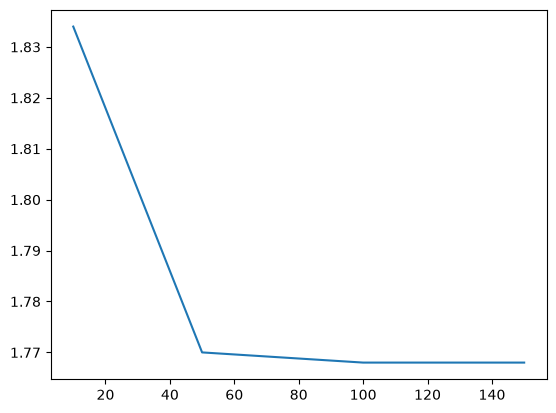

In [19]:
plt.plot(df_scores.n_estimators, df_scores.rmse)

In [20]:
## Question 4
scores = []

for d in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred)).round(3)

    
        scores.append((d, n, rmse))

In [21]:
columns = ['max_depth', 'n_estimators', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)

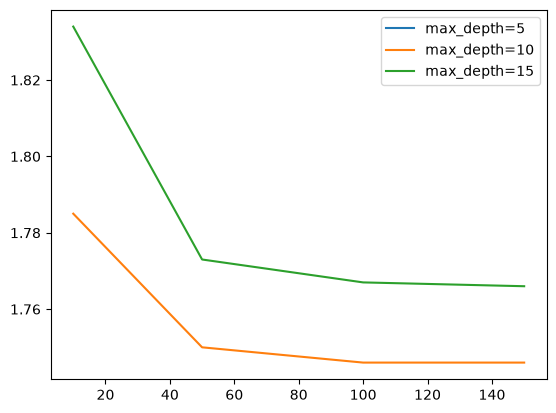

In [22]:
for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]
    
    plt.plot(df_subset.n_estimators, df_subset.rmse,
             label='max_depth=%d' % d)

plt.legend()

In [23]:
## Question 5 - feature importance
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)
print("RMSE:", np.sqrt(mean_squared_error(y_val, y_pred)))

RMSE: 1.830014488279621


In [24]:
rf.feature_importances_

array([0.05546622, 0.00787275, 0.0200048 , 0.00563607, 0.06100789,
       0.02112758, 0.16071286, 0.01168541, 0.07825357, 0.29582159,
       0.00693892, 0.01972375, 0.00647862, 0.00338878, 0.04223247,
       0.20364873])

In [25]:
feature_importance = pd.DataFrame({
    'Feature': dv.get_feature_names_out(),
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print(feature_importance)

                         Feature  Importance
9                     model_year    0.295822
15                vehicle_weight    0.203649
6             fuel_type=Gasoline    0.160713
8                     horsepower    0.078254
4            engine_displacement    0.061008
0                   acceleration    0.055466
14                    origin=USA    0.042232
5               fuel_type=Diesel    0.021128
2   drivetrain=Front-wheel drive    0.020005
11                     num_doors    0.019724
7               fuel_type=Hybrid    0.011685
1     drivetrain=All-wheel drive    0.007873
10                 num_cylinders    0.006939
12                   origin=Asia    0.006479
3    drivetrain=Rear-wheel drive    0.005636
13                 origin=Europe    0.003389


In [26]:
feature_importance.head(10)

,Feature,Importance
9,model_year,0.295822
15,vehicle_weight,0.203649
6,fuel_type=Gasoline,0.160713
8,horsepower,0.078254
4,engine_displacement,0.061008
0,acceleration,0.055466
14,origin=USA,0.042232
5,fuel_type=Diesel,0.021128
2,drivetrain=Front-wheel drive,0.020005
11,num_doors,0.019724


In [27]:
## Question 6 - XGBoost
!pip install xgboost
import xgboost as xgb


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


In [28]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [29]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [30]:
%%capture output

xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist)

In [31]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [32]:
df_score = parse_xgb_output(output)
df_score

,num_iter,train_rmse,val_rmse
0,0,2.40653,2.46782
1,5,1.59328,1.76216
2,10,1.47125,1.73205
3,15,1.41908,1.73512
4,20,1.39368,1.73766
5,25,1.35837,1.74359
6,30,1.33243,1.74548
7,35,1.29290,1.75198
8,40,1.25326,1.76296
9,45,1.21527,1.77244


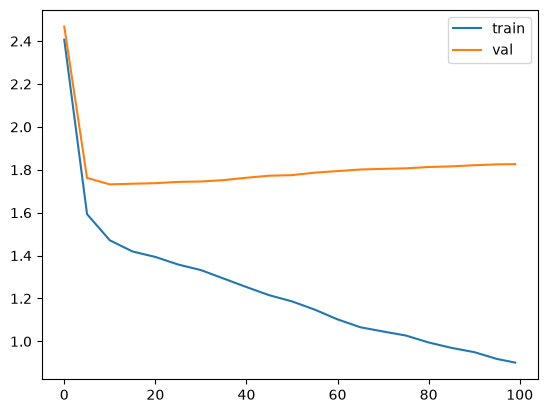

In [33]:
plt.plot(df_score.num_iter, df_score.train_rmse, label='train')
plt.plot(df_score.num_iter, df_score.val_rmse, label='val')
plt.legend()

In [34]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist)

In [35]:
df_score = parse_xgb_output(output)
df_score

,num_iter,train_rmse,val_rmse
0,0,2.74739,2.78635
1,5,2.12109,2.20428
2,10,1.80592,1.93152
3,15,1.64286,1.80346
4,20,1.55847,1.75076
5,25,1.50918,1.72751
6,30,1.47544,1.71667
7,35,1.44978,1.71287
8,40,1.43074,1.71289
9,45,1.41543,1.71310


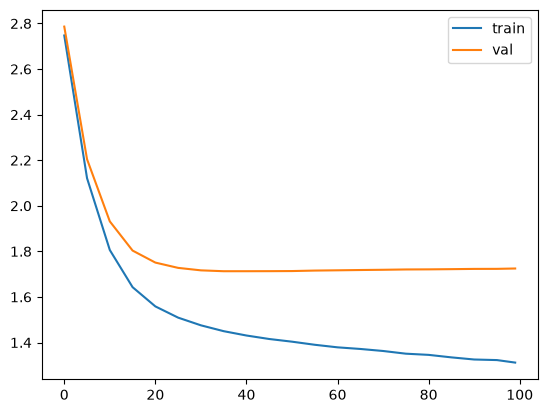

In [36]:
plt.plot(df_score.num_iter, df_score.train_rmse, label='train')
plt.plot(df_score.num_iter, df_score.val_rmse, label='val')
plt.legend()